In [17]:
import numpy as np
from sklearn import datasets
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# 1. Load data
digits = load_digits()
X, y = digits.data, digits.target  # X: (n_samples, 64)

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 3. Baseline: logistic regression on raw pixels
pipe_raw = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])

pipe_raw.fit(X_train, y_train)
y_pred_raw = pipe_raw.predict(X_test)
acc_raw = accuracy_score(y_test, y_pred_raw)

print(f"Test accuracy (raw pixels): {acc_raw:.3f}")
print(classification_report(y_test, y_pred_raw))

Test accuracy (raw pixels): 0.981
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        54
           1       0.95      0.95      0.95        55
           2       1.00      1.00      1.00        53
           3       1.00      1.00      1.00        55
           4       0.98      0.98      0.98        54
           5       1.00      0.98      0.99        55
           6       1.00      0.98      0.99        54
           7       1.00      1.00      1.00        54
           8       0.91      0.94      0.92        52
           9       0.98      0.98      0.98        54

    accuracy                           0.98       540
   macro avg       0.98      0.98      0.98       540
weighted avg       0.98      0.98      0.98       540



In [18]:
from sklearn.decomposition import PCA
import pandas as pd

# 4. Representation: PCA to 32 dimensions, then logistic regression
pipe_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=32, random_state=42)),
    ("logreg", LogisticRegression(max_iter=1000))
])

pipe_pca.fit(X_train, y_train)
y_pred_pca = pipe_pca.predict(X_test)
acc_pca = accuracy_score(y_test, y_pred_pca)

# 5. Put results in a small table
results = pd.DataFrame([
    {"Representation": "Raw pixels", "Dim": X.shape[1], "Test accuracy": acc_raw},
    {"Representation": "PCA(32)",   "Dim": 32,          "Test accuracy": acc_pca},
])

results

,Representation,Dim,Test accuracy
0,Raw pixels,64,0.981481
1,PCA(32),32,0.951852


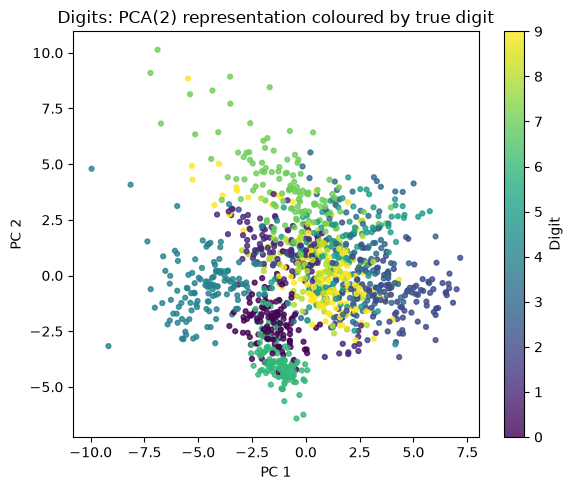

In [19]:
import matplotlib.pyplot as plt

# Fit PCA(2) on *train* data only for visualization
pca2 = PCA(n_components=2, random_state=42)
X_train_scaled = StandardScaler().fit_transform(X_train)
X_train_2d = pca2.fit_transform(X_train_scaled)

plt.figure(figsize=(6, 5))
scatter = plt.scatter(
    X_train_2d[:, 0], X_train_2d[:, 1],
    c=y_train, s=12, alpha=0.8
)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("Digits: PCA(2) representation coloured by true digit")
plt.colorbar(scatter, ticks=range(10), label="Digit")
plt.tight_layout()
plt.show()

In [20]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


# 1. Transforms & dataset (simple normalization)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

train_dataset = datasets.CIFAR10(
    root="data", train=True, download=True, transform=transform
)
test_dataset = datasets.CIFAR10(
    root="data", train=False, download=True, transform=transform
)

# Subsample train set for speed
subset_indices = torch.randperm(len(train_dataset))[:5000]
train_subset = Subset(train_dataset, subset_indices)

train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

In [21]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# 1. Transforms & dataset (simple normalization)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

train_dataset = datasets.CIFAR10(
    root="data", train=True, download=True, transform=transform
)
test_dataset = datasets.CIFAR10(
    root="data", train=False, download=True, transform=transform
)

# Subsample train set for speed
subset_indices = torch.randperm(len(train_dataset))[:5000]
train_subset = Subset(train_dataset, subset_indices)

train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

In [22]:
class SmallCNN(nn.Module):
    def __init__(self, feature_dim=256, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 8x8
        )
        self.flatten = nn.Flatten()
        self.fc = nn.Sequential(
            nn.Linear(64 * 8 * 8, feature_dim),
            nn.ReLU()
        )
        self.classifier = nn.Linear(feature_dim, num_classes)

    def forward(self, x, return_features=False):
        h = self.features(x)
        h = self.flatten(h)
        z = self.fc(h)              # representation
        logits = self.classifier(z) # head
        if return_features:
            return logits, z
        return logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SmallCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [23]:
def train_epoch(model, loader, optimizer, device):
    model.train()
    running_loss, running_correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == y).sum().item()
        total += x.size(0)

    return running_loss / total, running_correct / total

for epoch in range(5):  # a few epochs for demonstration
    loss, acc = train_epoch(model, train_loader, optimizer, device)
    print(f"Epoch {epoch+1}: loss={loss:.4f}, train_acc={acc:.3f}")

Epoch 1: loss=1.8532, train_acc=0.337
Epoch 2: loss=1.4437, train_acc=0.492
Epoch 3: loss=1.2539, train_acc=0.562
Epoch 4: loss=1.1114, train_acc=0.605
Epoch 5: loss=0.9800, train_acc=0.656


In [24]:
import numpy as np

def extract_representations(model, loader, device):
    model.eval()
    features_list, labels_list = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            logits, z = model(x, return_features=True)
            features_list.append(z.cpu().numpy())
            labels_list.append(y.numpy())
    return np.concatenate(features_list, axis=0), np.concatenate(labels_list, axis=0)

# 1. Extract train/test features
Z_train, y_train = extract_representations(model, train_loader, device)
Z_test,  y_test  = extract_representations(model, test_loader, device)

print("Train features shape:", Z_train.shape)  # e.g., (5000, 256)
print("Test features shape:", Z_test.shape)

Train features shape: (5000, 256)
Test features shape: (10000, 256)


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from tqdm import tqdm

# 2. Baseline: linear classifier on raw flattened pixels

# Build flattened pixel arrays for the *same* subsets
def collect_flat_pixels(loader):
    X_list, y_list = [], []
    for x, y in loader:
        # x: (B, C, H, W)
        X_list.append(x.view(x.size(0), -1).numpy())
        y_list.append(y.numpy())
    return np.concatenate(X_list, axis=0), np.concatenate(y_list, axis=0)

X_train_flat, y_train_flat = collect_flat_pixels(train_loader)
X_test_flat,  y_test_flat  = collect_flat_pixels(test_loader)

logreg_pixels = LogisticRegression(
    max_iter=1000
)
logreg_pixels.fit(X_train_flat, y_train_flat)
y_pred_pixels = logreg_pixels.predict(X_test_flat)
acc_pixels = accuracy_score(y_test_flat, y_pred_pixels)

# 3. Linear classifier on CNN representations
logreg_repr = LogisticRegression(
    max_iter=1000
)
logreg_repr.fit(Z_train, y_train)
y_pred_repr = logreg_repr.predict(Z_test)
acc_repr = accuracy_score(y_test, y_pred_repr)

print("Test accuracy (linear on pixels):", acc_pixels)
print("Test accuracy (linear on CNN features):", acc_repr)

Test accuracy (linear on pixels): 0.2812
Test accuracy (linear on CNN features): 0.5665


In [26]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

results = pd.DataFrame([
    {"Representation": "Flattened pixels", "Dim": X_train_flat.shape[1],
     "Test accuracy": acc_pixels},
    {"Representation": "CNN features",     "Dim": Z_train.shape[1],
     "Test accuracy": acc_repr},
])

results

,Representation,Dim,Test accuracy
0,Flattened pixels,3072,0.2812
1,CNN features,256,0.5665


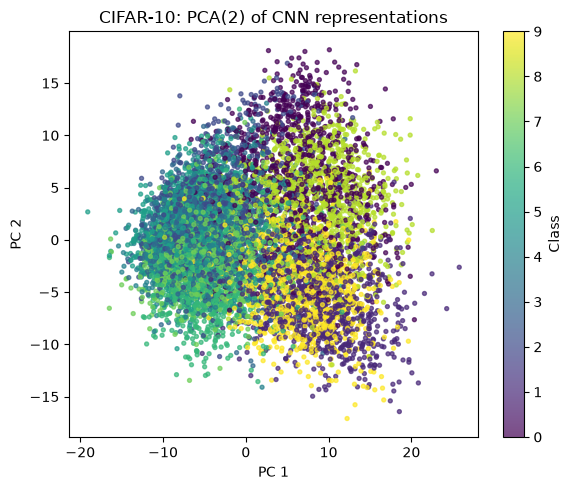

In [27]:
# 2D PCA of CNN features for visualization
pca2 = PCA(n_components=2, random_state=42)
Z_test_2d = pca2.fit_transform(Z_test)

plt.figure(figsize=(6, 5))
scatter = plt.scatter(
    Z_test_2d[:, 0], Z_test_2d[:, 1],
    c=y_test, s=8, alpha=0.7
)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("CIFAR-10: PCA(2) of CNN representations")
plt.colorbar(scatter, ticks=range(10), label="Class")
plt.tight_layout()
plt.show()